# Target-slack energy EMS: fixed 16 MW data center
One CPLEX solve minimizes excess exact-service failed hours, then normalized energy shortage with optional small throughput regularization. Native Parallel EGO minimizes HPP LCoE, using the existing `cost_aware_rational` score below target. Final acceptance uses physically validated hourly reliability with 0.001 MW tolerance.

A time-limited positive slack is an observed violation, not proof of infeasibility. The certificate bounds the minimum **excess exact-service failures**, not maximum availability or epsilon-based LOLH. With nonzero regularization the energy criterion has a small throughput trade-off; set kappa to zero for pure served-energy maximization. Strict simultaneous-operation validation remains enabled.


In [1]:
import os
os.environ['OPENMDAO_REPORTS'] = '0'
os.environ['PYTHONDONTWRITEBYTECODE'] = '1'
from pathlib import Path
from copy import deepcopy
import pandas as pd
import matplotlib.pyplot as plt
import hydesign
from hydesign.sizing_native_hpp_sizing_target_slack_energy import (
    read_configuration, run_fixed_design, run_lcoe_reliability_experiment,
    load_lcoe_reliability_experiment,
)
repo = Path(hydesign.__file__).resolve().parent.parent
config_path = repo / 'hydesign/examples/thesis_simple_datacenter/simple_datacenter.yml'


In [2]:
# All user-adjustable settings: YAML economics, technology and bounds + overrides.

reliability_targets = [
    0.40, 0.50, 0.60, 0.70,
    0.80, 0.90, 0.93, 0.95,
    0.97, 0.99, 0.999, 1.00
]

reliability_target = reliability_targets[0]
fixed_test_targets = []
search_budget_seconds = 1800  # 30 minutes per target

output_dir = repo / 'hpp_sizing_runs/lcoe_reliability_frontier_target_slack_energy'
saved_experiment = None  # Set a saved experiment path to load without any new solves.
regenerate_saved_figures = False
fixed_design = {'Nwt': 6, 'solar_MW [MW AC]': 52.86662334643591,
                'b_P [MW]': 58.833763458464084, 'b_E_h [h]': 2.0}

config = read_configuration(config_path)
config.update(
    facility_load_mw=16., pue=1.15, reliability_target=reliability_target,
    hpp_sizing_objective='minimize_lcoe',
    hpp_sizing_rejection_mode='cost_aware_rational',
    hpp_sizing_cost_aware_lambda_ref=10., hpp_sizing_cost_aware_lambda_min=.5,
    hpp_sizing_cost_aware_smoothing_hours=50.,
    ems_time_limit_seconds=30, ems_threads=1,
    ems_beta_energy_target_slack_energy=.25,
    ems_kappa_battery_target_slack_energy=.001,  # 0 disables throughput regularization.
    ems_mip_gap_target_slack_energy=1e-4, ems_seed_target_slack_energy=0,
    hpp_sizing_time_limit_seconds=search_budget_seconds,
    hpp_sizing_cleanup_seconds=10, hpp_sizing_recovery_time_limit_seconds=60,
    hpp_sizing_reporting_time_limit_seconds=30, hpp_sizing_heartbeat_seconds=10,
    hpp_sizing_prevent_sleep=True,
    n_doe=16, n_procs=2, n_clusters=2, max_iter=100,
    min_conv_iter=100, npred=10000, n_seed=0, tol=1e-6,
)
for name in ('Nwt', 'solar_MW [MW AC]', 'b_P [MW]', 'b_E_h [h]'):
    config['variables'][name]['var_type'] = 'design'


## Fixed-design checks
The 70% case should permit zero slack; the 99.9% case can return a valid below-target incumbent. Each test saves configuration, dispatch, solver bounds and a summary in a unique folder. Below-target designs remain available even though final sizing recovery cannot accept them.


In [3]:
""" if saved_experiment is None:
    fixed_results = []
    for target in dict.fromkeys(fixed_test_targets):
        test_config = deepcopy(config)
        test_config['reliability_target'] = target
        fixed_results.append(run_fixed_design(
            config_path, test_config, fixed_design, output_dir / 'fixed_checks_target_slack_energy'))
    display(pd.DataFrame(fixed_results)) """


" if saved_experiment is None:\n    fixed_results = []\n    for target in dict.fromkeys(fixed_test_targets):\n        test_config = deepcopy(config)\n        test_config['reliability_target'] = target\n        fixed_results.append(run_fixed_design(\n            config_path, test_config, fixed_design, output_dir / 'fixed_checks_target_slack_energy'))\n    display(pd.DataFrame(fixed_results)) "

## Small native EGO experiment
Only the selected target runs. The search has its own wall deadline; bounded recovery and reporting add time. New timestamped directories preserve previous runs. Candidate dispatches and scores are retained in `evaluations.csv` and atomic checkpoints. Idle sleep prevention is temporary; keep the computer awake during optimization.


In [4]:

if saved_experiment is None:
    experiment_dir = run_lcoe_reliability_experiment(
        config_path,
        config,
        reliability_targets,
        output_dir
    )
else:
    experiment_dir = Path(saved_experiment)

print('Saved experiment:', experiment_dir)


LCoE experiment: \\?\C:\Users\loict\OneDrive\Skrivebord\Master thesis\MSc Modelling\HyDesign\hpp_sizing_runs\lcoe_reliability_frontier_target_slack_energy\experiment_20261113_231302Z_119898d7_target_slack_energy
Target start UTC: 2026-11-13T23:13:06.004585+00:00 0.4
Native EGO results: \\?\C:\Users\loict\OneDrive\Skrivebord\Master thesis\MSc Modelling\HyDesign\hpp_sizing_runs\lcoe_reliability_frontier_target_slack_energy\experiment_20261113_231302Z_119898d7_target_slack_energy\reliability_040\20261113_231306Z_a52682e4_hpp_sizing_target_slack_energy
Outer wall-clock limit [s]: 1800
Search stopped: TIME_LIMIT -- bounded independent validation.
Target end UTC: 2026-11-13T23:43:16.962428+00:00 status: TIME_LIMIT evaluations: 413 best validated LCoE: 41.69876588249966
Target start UTC: 2026-11-13T23:43:16.979519+00:00 0.5
Native EGO results: \\?\C:\Users\loict\OneDrive\Skrivebord\Master thesis\MSc Modelling\HyDesign\hpp_sizing_runs\lcoe_reliability_frontier_target_slack_energy\experiment_20

## Results
The selected design must meet the reported reliability target and pass independent physical/cost validation. Saved results can be reloaded without optimization. With one target, the graph is one observed point, not a Pareto frontier. Full EMS slack and certificate diagnostics are in each run's result and evaluation history.


,reliability_target,target_reliability_percent,achieved_reliability_percent,lcoe_hpp_eur_per_mwh,annualized_cost_hpp,served_facility_energy_mwh,EENS,LOLH,Nwt,wind_MW,...,reliability_slack,binary_failed_hours,minimum_slack_lower_bound,minimum_slack_upper_bound,minimum_reliability_violation_certified,ems_status,ems_relative_gap,ems_seconds,ego_objective_score,nondominated
0,0.400,40.0,52.066210,41.698766,4.412596e+06,105820.791098,34339.208902,4199.0,5.0,25.0,...,0.0,4199,0,0,True,OPTIMAL_WITHIN_TOLERANCES,0.000000,0.703,41.698766,False
1,0.500,50.0,51.598174,41.718287,4.354279e+06,104373.384672,35786.615328,4240.0,5.0,25.0,...,0.0,4240,0,0,True,OPTIMAL_WITHIN_TOLERANCES,0.000000,0.625,41.718287,False
2,0.600,60.0,61.563927,41.698766,4.412596e+06,105820.791098,34339.208902,3367.0,5.0,25.0,...,0.0,3504,0,0,True,OPTIMAL_WITHIN_TOLERANCES,0.000000,1.312,41.698766,True
3,0.700,70.0,70.000000,42.894700,4.670258e+06,108877.276968,31282.723032,2628.0,5.0,25.0,...,0.0,2628,0,0,True,TIME_LIMIT_INCUMBENT,0.000899,30.062,42.894700,True
4,0.800,80.0,80.000000,51.188518,5.862845e+06,114534.370245,25625.629755,1752.0,5.0,25.0,...,0.0,1752,0,0,True,TIME_LIMIT_INCUMBENT,0.002387,30.047,51.188518,True
5,0.900,90.0,90.000000,55.711338,7.071203e+06,126925.747602,13234.252398,876.0,5.0,25.0,...,0.0,876,0,0,True,TIME_LIMIT_INCUMBENT,0.001089,30.016,55.711338,True
6,0.930,93.0,93.002283,60.388966,7.903478e+06,130876.190646,9283.809354,613.0,5.0,25.0,...,0.0,613,0,0,True,TIME_LIMIT_INCUMBENT,0.001382,30.047,60.388966,True
7,0.950,95.0,95.011416,76.693095,1.026643e+07,133863.758417,6296.241583,437.0,5.0,25.0,...,0.0,438,0,0,True,TIME_LIMIT_INCUMBENT,0.003015,30.031,76.693095,True
8,0.970,97.0,97.009132,80.147186,1.097062e+07,136880.957418,3279.042582,262.0,10.0,50.0,...,0.0,262,0,0,True,TIME_LIMIT_INCUMBENT,0.005026,30.031,80.147186,True
9,0.990,99.0,99.006849,90.355642,1.254385e+07,138827.485571,1332.514429,87.0,14.0,70.0,...,0.0,87,0,0,True,TIME_LIMIT_INCUMBENT,0.000783,30.047,90.355642,True


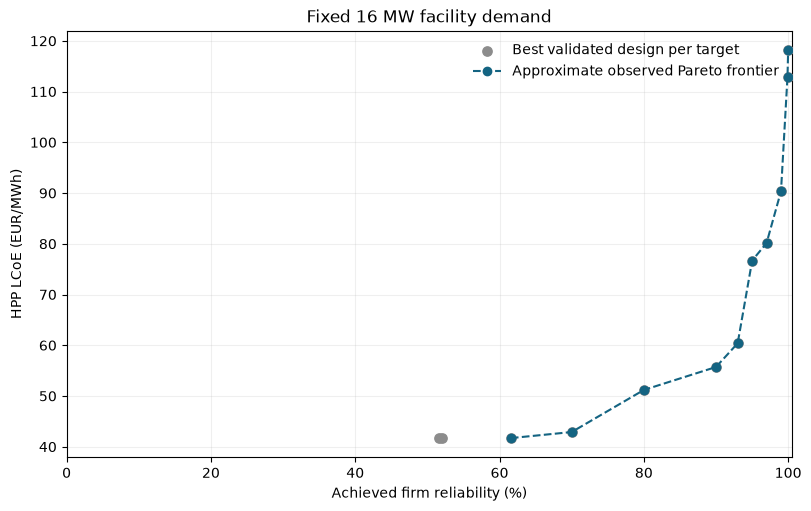

In [5]:
summary, figure = load_lcoe_reliability_experiment(
    experiment_dir, save_figures=bool(saved_experiment is not None and regenerate_saved_figures))
display(summary)
plt.show()
